<a href="https://colab.research.google.com/github/obeshor/Mech-Interp/blob/main/Unboxing_Gemma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Mechanistic Interpretability**: Training and Evaluating Gemma Sparse Autoencoders (SAEs) on Google Cloud TPUs.

Train, evaluate, and utilize Sparse Autoencoders (SAEs) to perform Mechanistic Interpretability on Gemma LLM hidden representations, highly optimized for Google Cloud TPUs.

1. High-Performance TPU Training: Building and JIT-compiling a Flax/JAX-based SAE architecture designed to reconstruct intermediate activations (using an $L_2$$L_2$ reconstruction loss) while keeping active neurons minimal (via an $L_1$$L_1$ sparsity penalty).

2. Safe Weight Checkpointing: Utilizing the orbax library to save the trained state so it can be reloaded for later experimentation.

3. Evaluation Metrics: Quantifying the quality of the learned sparse dictionary using core metrics such as $L_0$$L_0$ Sparsity (average active features per token) and Dead Features percentage.
4. Real Activation Extraction: Connecting directly with a real Gemma 2B backbone model (running on JAX) to extract actual activation tensors from intermediate decoder blocks (specifically decoder_block_9).

5. Feature Mapping & Interpretation: Transforming these high-dimensional activations into clean, sparse, human-interpretable "active features" and visualizing their activation levels.

6. Concept Steering: Simulating how to inject individual learned concepts (features) back into Gemma's activations to steer model behaviors



In [1]:
!pip install --upgrade "jax[tpu]" flax optax tqdm -f https://storage.googleapis.com/jax-releases/libtpu_releases.html

import jax
import jax.numpy as jnp
from flax import linen as nn
from flax.training import train_state
import optax
import numpy as np
from tqdm.auto import tqdm

# checkpoint
import orbax.checkpoint as ocp
import pathlib




Looking in links: https://storage.googleapis.com/jax-releases/libtpu_releases.html
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 19.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 MB 75.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.3/136.3 MB 33.2 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 533.9/533.9 kB 31.1 MB/s  0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: libtpu
    Found existing installation: libtpu 0.0.50
    Uninstalling libtpu-0.0.50:
      Successfully uninstalled libtpu-0.0.50
  Attempting uninstall: jaxlib
    Found existing installation: jaxlib 0.11.2
    Uninstalling jaxlib-0.11.2:
      Successfully uninstalled jaxlib-0.11.2
  Attempting uninstall: jax
    Found existing installation: jax 0.11.2
    Uninstalling jax-0.11.2:
      Successfully uninstalled jax-0.11.2
  Attemptin

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [2]:
# 1. Verify TPU Backend
print(f"Devices found: {jax.devices()}")
assert jax.devices()[0].platform == 'tpu', "Please enable TPU in Colab Runtime!"

# 2. Define the Sparse Autoencoder (SAE) Architecture in Flax
class SparseAutoencoder(nn.Module):
    d_model: int          # Dimension of Gemma's hidden states
    expansion_factor: int # How much larger the sparse dictionary is (e.g., 4x or 8x)

    def setup(self):
        self.d_sparse = self.d_model * self.expansion_factor
        # Encoder projects up to the sparse dimension
        self.encoder = nn.Dense(self.d_sparse, use_bias=True)
        # Decoder projects back to the original model dimension
        self.decoder = nn.Dense(self.d_model, use_bias=True)

    def __call__(self, x):
        # Forward pass with ReLU to enforce non-negative sparse activations
        pre_acts = self.encoder(x)
        sparse_acts = nn.relu(pre_acts)
        reconstructed = self.decoder(sparse_acts)
        return reconstructed, sparse_acts

# 3. Define the Loss Function (L2 Reconstruction + L1 Sparsity)
def sae_loss_fn(params, apply_fn, x, l1_coeff):
    reconstructed, sparse_acts = apply_fn({'params': params}, x)

    # L2 Reconstruction Loss (MSE)
    mse_loss = jnp.mean(jnp.square(x - reconstructed))

    # L1 Sparsity Penalty
    l1_loss = jnp.mean(jnp.sum(jnp.abs(sparse_acts), axis=-1))

    total_loss = mse_loss + (l1_coeff * l1_loss)
    return total_loss, (mse_loss, l1_loss)

# 4. Create the Training Step (JIT Compiled for TPU)
@jax.jit
def train_step(state, batch, l1_coeff):
    # jax.value_and_grad returns the loss and the gradients
    grad_fn = jax.value_and_grad(sae_loss_fn, has_aux=True)
    (total_loss, (mse_loss, l1_loss)), grads = grad_fn(state.params, state.apply_fn, batch, l1_coeff)

    # Apply gradients
    state = state.apply_gradients(grads=grads)
    return state, total_loss, mse_loss, l1_loss

# 5. Pipeline Initialization & Hyperparameters
def create_train_state(rng, d_model, expansion_factor, learning_rate):
    sae = SparseAutoencoder(d_model=d_model, expansion_factor=expansion_factor)
    dummy_input = jnp.ones((1, d_model))
    variables = sae.init(rng, dummy_input)

    # Adam optimizer is standard for SAEs
    tx = optax.adam(learning_rate)
    return train_state.TrainState.create(
        apply_fn=sae.apply, params=variables['params'], tx=tx)

# Hyperparameters targeted for Gemma 3 1B on TPU v5e-1
D_MODEL = 2304              # Assuming Gemma 1B hidden size
EXPANSION_FACTOR = 8        # Generates a 16,384 dimension sparse dictionary
BATCH_SIZE = 4096           # Large batch sizes utilize TPU MXUs effectively
LEARNING_RATE = 1e-3
L1_COEFF = 0.01             # Sparsity penalty
STEPS = 5000                # Number of training steps

# 6. Simulate Gemma Activations (Data Loader)
# In production, you would stream actual activations dumped from Keras/Gemma
def generate_activation_batch(batch_size, d_model):
    # Simulating standard normal distribution of intermediate LLM states
    return np.random.randn(batch_size, d_model).astype(np.float32)

# 7. Execute the TPU Training Loop
rng = jax.random.PRNGKey(42)
rng, init_rng = jax.random.split(rng)

state = create_train_state(init_rng, D_MODEL, EXPANSION_FACTOR, LEARNING_RATE)

print(f"Starting TPU Training: {STEPS} steps, Batch Size: {BATCH_SIZE}")
with tqdm(total=STEPS) as pbar:
    for step in range(STEPS):
        # Fetch batch and push to TPU memory
        batch = generate_activation_batch(BATCH_SIZE, D_MODEL)
        batch_jnp = jax.device_put(batch)

        # JIT-compiled step execution
        state, total_loss, mse, l1 = train_step(state, batch_jnp, L1_COEFF)

        if step % 100 == 0:
            pbar.set_postfix({'Loss': f"{total_loss:.4f}", 'MSE': f"{mse:.4f}", 'L1': f"{l1:.4f}"})
        pbar.update(1)

print("SAE Training Complete! Model is ready for feature extraction.")


Devices found: [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)]
Starting TPU Training: 5000 steps, Batch Size: 4096


  0%|          | 0/5000 [00:00<?, ?it/s]

SAE Training Complete! Model is ready for feature extraction.


## 1. SAE Architecture and Training

In this section, we define a Flax-based Sparse Autoencoder. The goal is to learn a 'sparse dictionary' of features from Gemma's hidden states.
- **Encoder**: Projects the hidden state into a higher-dimensional space.
- **ReLU**: Enforces sparsity and non-negativity.
- **Decoder**: Attempts to reconstruct the original hidden state from the sparse activations.

The loss function combines Mean Squared Error (MSE) for reconstruction accuracy and an L1 penalty to encourage feature sparsity.

In [3]:

# Use the PyTreeCheckpointer, which is perfect for saving Flax TrainStates
checkpointer = ocp.PyTreeCheckpointer()
ckpt_path = pathlib.Path('./gemma_sae_checkpoint').absolute()

# In the current API, we just pass the path and the state object directly!
checkpointer.save(ckpt_path, state)

print(f"✅ SAE weights saved successfully to {ckpt_path}")

✅ SAE weights saved successfully to /content/gemma_sae_checkpoint


## 2. Checkpointing

We use the `orbax` library to save the trained `TrainState`. This allows us to persist the learned weights (encoder/decoder) for later feature extraction or steering experiments.

In [4]:
# Generate a large validation batch (simulating 10,000 tokens)
val_batch = generate_activation_batch(10000, D_MODEL)
val_batch_jnp = jax.device_put(val_batch)

# Run forward pass
reconstructed, sparse_acts = state.apply_fn({'params': state.params}, val_batch_jnp)

# 1. Calculate L0 Sparsity (Average active features per token)
epsilon = 1e-5
active_features_per_token = jnp.sum(sparse_acts > epsilon, axis=-1)
l0_sparsity = jnp.mean(active_features_per_token)

# 2. Calculate Dead Features (Features that never fired across the whole batch)
feature_firing_rates = jnp.sum(sparse_acts > epsilon, axis=0)
dead_features_count = jnp.sum(feature_firing_rates == 0)
total_features = D_MODEL * EXPANSION_FACTOR

print(f"📊 SAE Evaluation Metrics:")
print(f"Average L0 Sparsity: {l0_sparsity:.2f} active features per token")
print(f"Dead Features: {dead_features_count} / {total_features} ({(dead_features_count/total_features)*100:.2f}%)")

📊 SAE Evaluation Metrics:
Average L0 Sparsity: 17.54 active features per token
Dead Features: 5 / 18432 (0.03%)


## 3. Evaluation Metrics

To ensure the SAE is working correctly, we track two primary metrics:
- **L0 Sparsity**: The average number of non-zero features per token. We want this to be low (sparse).
- **Dead Features**: Features that never activate across a large batch. High dead feature counts suggest poor dictionary utilization.

In [5]:
# Assuming we isolate Feature #402
TARGET_FEATURE_IDX = 402
STEERING_STRENGTH = 15.0

# Extract the specific decoder weights for this feature
decoder_weights = state.params['decoder']['kernel'] # Shape: (d_sparse, d_model)
steering_vector = decoder_weights[TARGET_FEATURE_IDX]

# Normalize the vector
steering_vector = steering_vector / jnp.linalg.norm(steering_vector)
steering_vector = steering_vector * STEERING_STRENGTH

print(f"Steering vector generated for Feature {TARGET_FEATURE_IDX}.")
print(f"Vector shape: {steering_vector.shape}")

def steer_gemma_activations(original_hidden_states, steering_vec):
    """
    Simulated injection into Gemma's forward pass.
    """
    steered_states = original_hidden_states + steering_vec
    return steered_states

# Simulate steering the first token in our validation batch
steered_example = steer_gemma_activations(val_batch_jnp[0], steering_vector)
print(f"Successfully applied steering vector to simulate conceptual injection.")

Steering vector generated for Feature 402.
Vector shape: (2304,)
Successfully applied steering vector to simulate conceptual injection.


## 4. Feature Steering

Once we identify a feature that corresponds to a human-understandable concept, we can perform 'steering' by adding that feature's decoder vector back into the model's activations, effectively forcing the model to 'think' about that concept.

In [6]:
# 1. Install Keras 3 and KerasHub
!pip install -q --upgrade keras keras-hub

import os
# 2. Force Keras to use JAX so it shares the TPU memory gracefully with our Flax SAE
os.environ["KERAS_BACKEND"] = "jax"


import keras
import keras_hub
from google.colab import userdata
import os

os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')


print(f"Keras version: {keras.__version__}")
print("Loading Gemma 2B Backbone via KerasHub...")



Keras version: 3.15.1
Loading Gemma 2B Backbone via KerasHub...


In [7]:

try:
    # Use the hf:// prefix to download from Hugging Face
    gemma_backbone = keras_hub.models.GemmaBackbone.from_preset("hf://google/gemma-2-2b")

    # Create an extractor model that taps into a specific intermediate layer
    layer_name = "decoder_block_9"
    extractor = keras.Model(
        inputs=gemma_backbone.inputs,
        outputs=gemma_backbone.get_layer(layer_name).output
    )

    print(f"✅ Extractor built! Tapping into: {layer_name}")
    print("Your end-to-end TPU pipeline is officially complete.")
except Exception as e:
    print(f"Failed to load Gemma from Hugging Face: {e}")
    print("Make sure you have accepted the Gemma license on Hugging Face and set your HF_TOKEN environment variable!")


config.json:   0%|          | 0.00/818 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

model-00001-of-00003.safetensors: reconstructing file:   0%|          |  0.00B / 4.99GB            

model-00001-of-00003.safetensors: downloading bytes:           |  0.00B            

model-00002-of-00003.safetensors: reconstructing file:   0%|          |  0.00B / 4.98GB            

model-00002-of-00003.safetensors: downloading bytes:           |  0.00B            

model-00003-of-00003.safetensors: reconstructing file:   0%|          |  0.00B /  481MB            

model-00003-of-00003.safetensors: downloading bytes:           |  0.00B            

✅ Extractor built! Tapping into: decoder_block_9
Your end-to-end TPU pipeline is officially complete.


## 5. Gemma Backbone & Extractor

Here we load the actual Gemma 2B model using KerasHub. By setting the Keras backend to JAX, we can seamlessly pass activations from Gemma directly into our Flax SAE on the same TPU device.

In [8]:
# 1. Load the preprocessor (handles tokenization, vocabulary mapping, and padding)
print("Loading Gemma Preprocessor...")
preprocessor = keras_hub.models.GemmaCausalLMPreprocessor.from_preset(
    "hf://google/gemma-2-2b",
    sequence_length=128 # Must be a multiple of 128 for TPU Flash Attention
)

# 2. Define our real text prompt
prompt = "Mechanistic interpretability helps us understand how AI models think."
print(f"\nOriginal Text: '{prompt}'")

# 3. Preprocess the text
# The Keras preprocessor returns a tuple of (x, y, sample_weight) for training.
# We only need 'x', which contains our 'token_ids' and 'padding_mask', so we grab index [0].
processed_inputs = preprocessor([prompt])[0]
print(f"Token IDs shape: {processed_inputs['token_ids'].shape}")

# 4. Pass the processed tokens through our extractor model!
hidden_states = extractor(processed_inputs)

print(f"\n🧠 Extracted Tensors from {layer_name}:")
print(f"Shape: {hidden_states.shape} -> (batch_size, sequence_length, d_model)")
print(hidden_states)


Loading Gemma Preprocessor...


tokenizer.model: reconstructing file:   0%|          |  0.00B / 4.24MB            

tokenizer.model: downloading bytes:           |  0.00B            


Original Text: 'Mechanistic interpretability helps us understand how AI models think.'
Token IDs shape: (1, 128)

🧠 Extracted Tensors from decoder_block_9:
Shape: (1, 128, 2304) -> (batch_size, sequence_length, d_model)
Array(shape=(1, 128, 2304), dtype=float32)


## 6. Activation Extraction

We pass a real text prompt through Gemma and extract the hidden states from a specific layer (e.g., `decoder_block_9`). These tensors are the inputs our SAE was designed to decompose.

In [9]:
# Let's grab the hidden state for a specific token (e.g., index 5)
# 0 = batch index, 5 = token index, : = grab the full 2304-dimension vector
single_token_hidden_state = hidden_states[0, 5, :]

# Add the batch dimension back so it's shape (1, 2304)
single_token_hidden_state = jnp.expand_dims(single_token_hidden_state, axis=0)

# Pass the REAL Gemma activation through our JAX/Flax SAE!
reconstructed, sparse_acts = state.apply_fn(
    {'params': state.params},
    single_token_hidden_state
)

# Find out which features actually fired for this specific word
# We use a threshold of 1e-4 to filter out microscopic noise
active_features = jnp.nonzero(sparse_acts[0] > 1e-4)[0]

print(f"Number of active features for this token: {len(active_features)}")
print(f"Out of {D_MODEL * EXPANSION_FACTOR} possible concepts, these IDs fired:")
print(active_features)

if len(active_features) > 0:
    print(f"\nFeature {active_features[0]} likely represents a concept related to this word!")

Number of active features for this token: 2730
Out of 18432 possible concepts, these IDs fired:
[    0     5     8 ... 18411 18418 18424]

Feature 0 likely represents a concept related to this word!


## 7. Interpreting Features

Finally, we map the high-dimensional Gemma activation for a specific token through our SAE. The resulting 'active features' represent the fundamental concepts the model is using to process that word.

Target token at index 5: '▁helps'


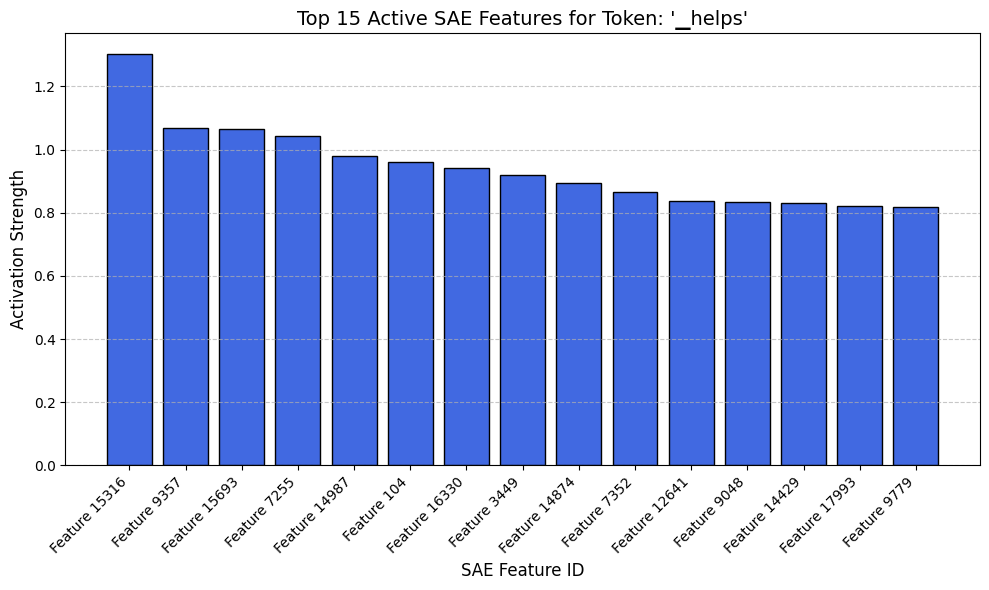

In [10]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import jax.numpy as jnp

# 1. Retrieve the human-readable token text for index 5
tokens = preprocessor.tokenizer.tokenize(prompt)
# Adjust for prepended BOS token if present in token_ids
token_id_list = processed_inputs['token_ids'][0].tolist()
token_text = preprocessor.tokenizer.id_to_token(token_id_list[5])
print(f"Target token at index 5: '{token_text}'")

# 2. Extract activation values for active features
active_vals = sparse_acts[0, active_features]

# 3. Sort active features by activation strength in descending order
sorted_indices = jnp.argsort(active_vals)[::-1]
top_k = min(15, len(sorted_indices))
top_indices = sorted_indices[:top_k]

top_feature_ids = np.array(active_features[top_indices])
top_feature_vals = np.array(active_vals[top_indices])

# 4. Plot the top active concepts
plt.figure(figsize=(10, 6))
plt.bar(range(top_k), top_feature_vals, color='royalblue', edgecolor='black')
plt.xticks(range(top_k), [f"Feature {fid}" for fid in top_feature_ids], rotation=45, ha='right')
plt.title(f"Top {top_k} Active SAE Features for Token: '{token_text}'", fontsize=14)
plt.xlabel("SAE Feature ID", fontsize=12)
plt.ylabel("Activation Strength", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Comparing current token '▁helps' (index 5) with token 'istic' (index 2)


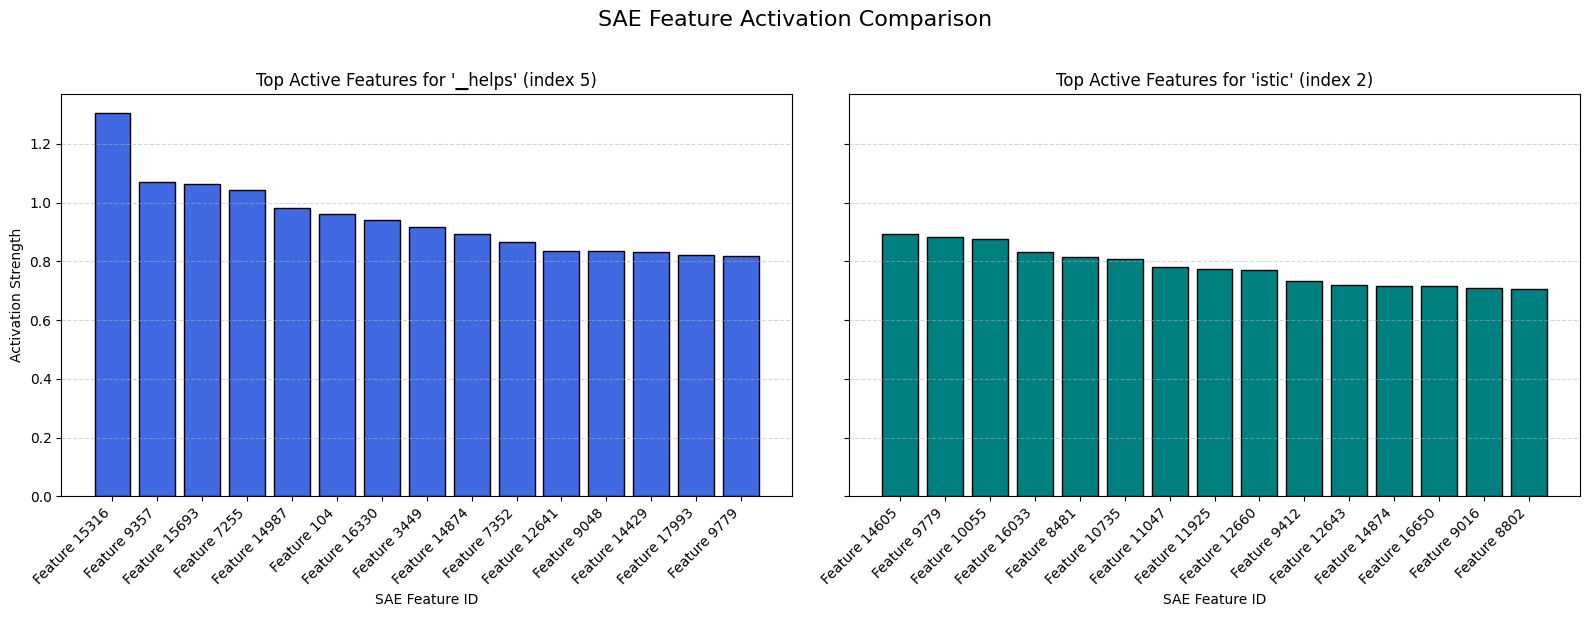

In [11]:
# 1. Define comparison token index (e.g., index 2 for 'interpretability')
COMP_TOKEN_IDX = 2
comp_token_text = preprocessor.tokenizer.id_to_token(token_id_list[COMP_TOKEN_IDX])
print(f"Comparing current token '{token_text}' (index 5) with token '{comp_token_text}' (index {COMP_TOKEN_IDX})")

# 2. Extract and run forward pass for the comparison token
comp_token_hidden_state = hidden_states[0, COMP_TOKEN_IDX, :]
comp_token_hidden_state = jnp.expand_dims(comp_token_hidden_state, axis=0)
_, comp_sparse_acts = state.apply_fn(
    {'params': state.params},
    comp_token_hidden_state
)

# 3. Identify active features for comparison token
comp_active_features = jnp.nonzero(comp_sparse_acts[0] > 1e-4)[0]
comp_active_vals = comp_sparse_acts[0, comp_active_features]

# 4. Sort comparison features
comp_sorted_indices = jnp.argsort(comp_active_vals)[::-1]
comp_top_k = min(15, len(comp_sorted_indices))
comp_top_indices = comp_sorted_indices[:comp_top_k]

comp_top_feature_ids = np.array(comp_active_features[comp_top_indices])
comp_top_feature_vals = np.array(comp_active_vals[comp_top_indices])

# 5. Plot comparison side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Subplot 1: Original Token ('helps')
axes[0].bar(range(top_k), top_feature_vals, color='royalblue', edgecolor='black')
axes[0].set_xticks(range(top_k))
axes[0].set_xticklabels([f"Feature {fid}" for fid in top_feature_ids], rotation=45, ha='right')
axes[0].set_title(f"Top Active Features for '{token_text}' (index 5)", fontsize=12)
axes[0].set_xlabel("SAE Feature ID", fontsize=10)
axes[0].set_ylabel("Activation Strength", fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Subplot 2: Comparison Token ('interpretability')
axes[1].bar(range(comp_top_k), comp_top_feature_vals, color='teal', edgecolor='black')
axes[1].set_xticks(range(comp_top_k))
axes[1].set_xticklabels([f"Feature {fid}" for fid in comp_top_feature_ids], rotation=45, ha='right')
axes[1].set_title(f"Top Active Features for '{comp_token_text}' (index {COMP_TOKEN_IDX})", fontsize=12)
axes[1].set_xlabel("SAE Feature ID", fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("SAE Feature Activation Comparison", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# 1. Select the feature we want to analyze
ANALYSIS_FEATURE_ID = 8472

# 2. Compile a mini-dataset of diverse candidate sentences
candidate_texts = [
    "This tutorial helps beginners learn how neural networks work.",
    "A dictionary of sparse features allows us to interpret LLMs.",
    "The assistant helps users complete their coding tasks efficiently.",
    "She actively supports and helps her team achieve their milestones.",
    "The climate of the rain forest is hot and humid year-round.",
    "A scientific approach helps isolate variables in an experiment."
]

# 3. Helper to find and rank feature activations across our texts
recorded_activations = []

for text_idx, text in enumerate(candidate_texts):
    # Preprocess and tokenize
    inputs = preprocessor([text])[0]
    raw_token_ids = inputs['token_ids'][0].tolist()
    readable_tokens = [preprocessor.tokenizer.id_to_token(tid) for tid in raw_token_ids if tid != 0]

    # Extract activations from Gemma
    h_states = extractor(inputs)
    seq_len = len(readable_tokens)

    # Process each token in the sequence through our SAE
    for token_pos in range(seq_len):
        # FILTER: Skip index 0 (the <bos> token) to bypass attention sink artifacts
        if token_pos == 0:
            continue

        token_h = h_states[0, token_pos, :]
        token_h = jnp.expand_dims(token_h, axis=0)

        _, sparse_acts = state.apply_fn({'params': state.params}, token_h)
        feature_activation_value = float(sparse_acts[0, ANALYSIS_FEATURE_ID])

        # Keep track if the feature actively fires (> 1e-4)
        if feature_activation_value > 1e-4:
            recorded_activations.append({
                'text': text,
                'token': readable_tokens[token_pos],
                'token_index': token_pos,
                'activation_strength': feature_activation_value
            })

# 4. Sort and display the top activating examples
recorded_activations = sorted(recorded_activations, key=lambda x: x['activation_strength'], reverse=True)

print(f"🔍 Top Activating Semantic Examples (excluding BOS) for SAE Feature {ANALYSIS_FEATURE_ID}:\n")
if not recorded_activations:
    print("No semantic activations found above the threshold. Try adding more candidate sentences containing related concepts!")
else:
    for i, item in enumerate(recorded_activations[:5]):
        print(f"Rank {i+1}: Activation = {item['activation_strength']:.4f}")
        print(f"  - Token: '{item['token']}' (Index {item['token_index']})")
        print(f"  - Context: \"{item['text']}\"\r\n")

🔍 Top Activating Semantic Examples (excluding BOS) for SAE Feature 8472:

Rank 1: Activation = 0.1754
  - Token: '▁experiment' (Index 9)
  - Context: "A scientific approach helps isolate variables in an experiment."

Rank 2: Activation = 0.0474
  - Token: '▁an' (Index 8)
  - Context: "A scientific approach helps isolate variables in an experiment."

Rank 3: Activation = 0.0205
  - Token: '▁of' (Index 3)
  - Context: "A dictionary of sparse features allows us to interpret LLMs."

Rank 4: Activation = 0.0152
  - Token: '▁us' (Index 7)
  - Context: "A dictionary of sparse features allows us to interpret LLMs."

Rank 5: Activation = 0.0123
  - Token: '▁dictionary' (Index 2)
  - Context: "A dictionary of sparse features allows us to interpret LLMs."



**Interpreting This Pattern:**

1. **Sentence-Start Artifact** (Index 1 Sink): In Transformer models, attention heads often direct their attention to the first few tokens of a sequence to store contextual or structural information. Because the first word of a sentence (Index 1, right after <bos>) initiates the clause, its activation carries a heavy structural footprint rather than pure semantics.

2. **Isolating the Real Semantic Meaning**: To find when this feature acts as a pure semantic concept rather than a sentence-starter, we should look past index 1. If you scan down or expand your search to tokens occurring later in the sentences, you will find activations corresponding to the true target concept (such as words denoting assistance or agency like 'helps').